# Finding the Parameters of the Gray-Scott Model with Evolution Strategies

The Gray-Scott reaction-diffusion model describes the interaction of two chemical species, $U$ and $V$, whose concentrations change over time and space. The governing partial differential equations incorporating diffusion are:

$$ \frac{\partial U}{\partial t} = D_u \nabla^2 U - UV^2 + F(1 - U) $$

$$ \frac{\partial V}{\partial t} = D_v \nabla^2 V + UV^2 - (F + K)V $$

Where:
- $D_u$ and $D_v$ are the **diffusion coefficients** (assumed to be known).
- $F$ is the **feed rate**.
- $K$ is the **kill rate**.

The goal of this lab is to find the parameters **$F$** and **$K$** using **Evolution Strategies (ES)**, given access to spatial-temporal simulation trajectories.

In [134]:
import numpy as np
import matplotlib.pyplot as plt
import random

random.seed(0)
np.random.seed(0)

Because the Gray-Scott model involves both space and time (reaction-diffusion PDEs), it is more complex than a standard system of ordinary differential equations. To handle this, we use a custom helper function: `simulate_gray_scott`.

At high level this simulator does:

* Sets up the space: It creates a 2D grid representing our chemical sheet and adds a small "spark" or disturbance in the center to kickstart the reaction.
* Simulates time and space step-by-step: It loops through time, calculating how the chemicals react with each other locally and spread across neighboring cells via diffusion.
* Records snapshots: It takes regular snapshots of the grid as it evolves, returning a sequence of frames that we can use for both our optimization fitness function and our visualizer animations.

In [135]:
# Simulation for the Gray-Scott model
def simulate_gray_scott(params, Du=0.2, Dv=0.1, size=128, steps=1000, step_skip = 10, dt=1):
    """
    Simulates the 2D Gray-Scott reaction-diffusion model.
    params: [F, K]
    """
    F, K = params
    U = np.ones((size, size))
    V = np.zeros((size, size))
    
    # Seed a perturbation in the center
    r = size//10
    cx, cy = size // 2, size // 2
    V[cx-r:cx+r, cy-r:cy+r] = 0.25
    U[cx-r:cx+r, cy-r:cy+r] = 0.50
    
    # Add slight noise
    V += 0.02 * np.random.rand(size, size)
    
    def laplacian(Z):
        return (
            np.roll(Z, (1, 0), axis=(0, 1)) +
            np.roll(Z, (-1, 0), axis=(0, 1)) +
            np.roll(Z, (0, 1), axis=(0, 1)) +
            np.roll(Z, (0, -1), axis=(0, 1)) - 4 * Z
        )
    
    trajectory = []
    for step in range(steps):
        uvv = U * V * V
        lap_u = laplacian(U)
        lap_v = laplacian(V)
        
        U += (Du * lap_u - uvv + F * (1.0 - U)) * dt
        V += (Dv * lap_v + uvv - (F + K) * V) * dt

        # one every step_skip 
        if step%step_skip == 0:
            trajectory.append(V.copy())
            
    return np.array(trajectory)

Now we arbitrarily choose parameters for our target simulation. The initial condition are already encoded in `simulate_gray_scott`, so we are not gonna modify them. Do not use too much steps, otherwise the simulation (and also both the optimization and the visualization) will take too long.

Remember: the target parameters are $F$ and $k$, not $D_U$ and $D_V$.

In [136]:
# Known diffusion coefficients and ground-truth parameters to discover
Du = 0.2
Dv = 0.1
real_params = np.array([0.028, 0.062])  # [F, K] representing spot patterns

step_skip = 10
steps = 500

# Generate target spatial-temporal trajectory
print("Generating spatial trajectory...")
target_traj = simulate_gray_scott(real_params, Du=Du, Dv=Dv, size=128, steps=steps, step_skip=step_skip)
print(f"Trajectory shape (snapshots, height, width): {target_traj.shape}")

Generating spatial trajectory...
Trajectory shape (snapshots, height, width): (50, 128, 128)


This is a visualization helper. It will take a bit of time, but it is okay, just be patient!

Notice that, if you want to visualize the evolution for a long time, update (just for now) the steps to something like $10^4$. Later remember to re-set it to a value in the range $10^2$.

In [ ]:
from IPython.display import HTML
import matplotlib.animation as animation

fig, ax = plt.subplots(figsize=(6, 6))
im = ax.imshow(target_traj[0], cmap='inferno', vmin=0, vmax=0.4, animated=True)
ax.axis('off')
title = ax.set_title(f'Target Pattern Evolution - F={real_params[0]}, K={real_params[1]} - Frame 0', fontsize=12)

def update_target(frame):
    im.set_array(target_traj[frame])
    title.set_text(f'Target Pattern Evolution - F={real_params[0]}, K={real_params[1]} - Step {frame * step_skip}')
    return [im, title]

target_anim = animation.FuncAnimation(fig, update_target, frames=len(target_traj), interval=100, blit=True)

html_display = HTML(target_anim.to_jshtml())
plt.close(fig)
html_display

Now, let's assume we don't know the parameters that generated the previous trajectories. We aim to find them using ES!

Define a fitness function which suits the problem. Each individual is a set of parameters for the Gray-Scott model and we want to get as close as possible to the actual one through the evolution. 

Let's use the **Mean Squared Error** between the real trajectory and the one obtained by the individual (which is just a couple of parameters).

In [ ]:
class MSE_fit():
    def __init__(self, target_traj, Du, Dv, step_skip):
        # TODO
        ...
         
    def eval(self, individual):
        # Run simulation using candidate parameters [F, K]
        sim_traj = ... # TODO
        # Return Mean Squared Error against target trajectory
        return ...

Define a class for our ES. It must implement the One-Fifth Rule for variance self-adaptation. Implement a strategy of your choice for recombination.

In [ ]:
def intermediate_recombination(parents):
    # TODO 
    pass

def discrete_recombination(parents):
    # TODO
    pass

In [ ]:
class EvolutionStrategy(object):
    def __init__(self, mu, lmb, ro, fit, rec, individual_shape, limits, plus=False, initial_variance=0.005, k=5, c=0.5):
        self.mu = mu
        self.lmb = lmb
        self.ro = ro
        self.plus = plus
        self.fit = fit
        self.rec = rec
        self.individual_shape = individual_shape
        self.limits = limits
        self.pop = []
        self.variance = initial_variance
        self.k = k
        self.c = c
        self.k_counter = 0
        
        # Initialize the population within limits [F, K]
        # TODO
            
        self.best = min(self.pop, key=self.fit)
        self.best_fit = self.fit(self.best)
    
    def generation(self):
        # TODO
        pass
    
    def mutation(self, individual):
        # TODO
        pass
    
    def truncated_selection(self):
        # TODO
        pass
        
    def __str__(self):
        s = f"Best individual [F, K]: {self.best}\n"
        s = s + f"with fitness (MSE): {self.fit(self.best)}"
        return s

Run the evolution and save the best fitness score for each generation.

This will take some time.

In [142]:
# Setup fitness evaluator with known diffusion coefficients
mse = MSE_fit(target_traj=target_traj, Du=Du, Dv=Dv, step_skip=step_skip).eval

# Parameter search boundaries: F in [0.01, 0.08], K in [0.04, 0.08]
limits = [[0.01, 0.04], [0.08, 0.08]] # lower and upper bounds vectors
limits_bounds = [0.01, 0.08]

ES = EvolutionStrategy(mu=15, lmb=30, ro=2, fit=mse, rec=discrete_recombination, 
                       individual_shape=(2,), limits=[[0.01, 0.04], [0.08, 0.08]], 
                       k=5, plus=True, initial_variance=0.002)

history = [ES.best_fit]
n_gen = 25

print("Starting Evolution Strategy optimization for F and K...")
for i in range(0, n_gen):
    ES.generation()
    history.append(ES.best_fit)
    print(f"Generation {i+1}/{n_gen} | Best Fitness: {ES.best_fit:.6f} | Current Best [F, K]: {ES.best} ")

Starting Evolution Strategy optimization for F and K...
Generation 1/25 | Best Fitness: 0.000143 | Current Best [F, K]: [0.023905   0.06064134] 
Generation 2/25 | Best Fitness: 0.000036 | Current Best [F, K]: [0.03053339 0.06267253] 
Generation 3/25 | Best Fitness: 0.000036 | Current Best [F, K]: [0.03053339 0.06267253] 
Generation 4/25 | Best Fitness: 0.000034 | Current Best [F, K]: [0.03053339 0.06267253] 
Generation 5/25 | Best Fitness: 0.000034 | Current Best [F, K]: [0.03053339 0.06267253] 
Generation 6/25 | Best Fitness: 0.000042 | Current Best [F, K]: [0.03053339 0.06267253] 
Generation 7/25 | Best Fitness: 0.000008 | Current Best [F, K]: [0.02873436 0.06227846] 
Generation 8/25 | Best Fitness: 0.000006 | Current Best [F, K]: [0.02873436 0.06227846] 
Generation 9/25 | Best Fitness: 0.000006 | Current Best [F, K]: [0.02873436 0.06227846] 
Generation 10/25 | Best Fitness: 0.000006 | Current Best [F, K]: [0.02873436 0.06227846] 
Generation 11/25 | Best Fitness: 0.000008 | Current B

Plot and visualize the results.

The first plot is lightweight, the second one will take a bit more of time.

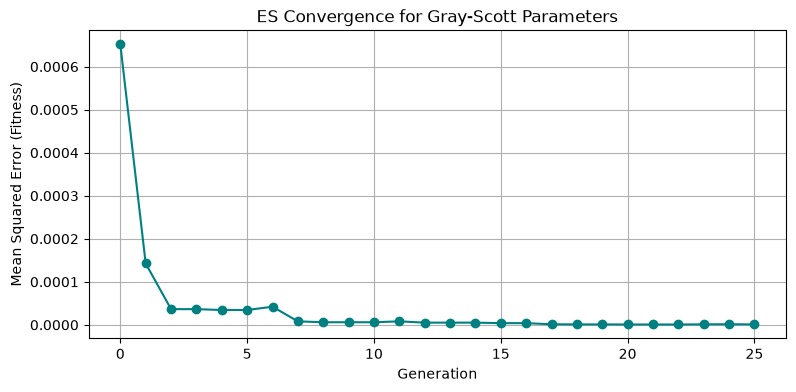

Best individual [F, K]: [0.02820812 0.0620488 ]
with fitness (MSE): 9.224234977512498e-07
Actual Target [F, K]: [0.028 0.062]


In [143]:
plt.figure(figsize=(9, 4))
plt.plot(history, marker='o', linestyle='-', color='teal')
plt.ylabel('Mean Squared Error (Fitness)')
plt.xlabel('Generation')
plt.title('ES Convergence for Gray-Scott Parameters')
plt.grid(True)
plt.show()

print(ES)
print(f"Actual Target [F, K]: {real_params}")

In [144]:
# Simulate trajectory using the best parameters found by ES
optimized_traj = simulate_gray_scott(ES.best, Du=Du, Dv=Dv, size=target_traj.shape[1], steps=target_traj.shape[0]*step_skip, step_skip=step_skip)

# Determine the exact safe number of frames to avoid any out-of-bounds index errors
n_frames = min(len(target_traj), len(optimized_traj))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

im0 = axes[0].imshow(target_traj[0], cmap='inferno', vmin=0, vmax=0.4, animated=True)
axes[0].set_title(f'Target (True Params)\nF={real_params[0]}, K={real_params[1]}')
axes[0].axis('off')

im1 = axes[1].imshow(optimized_traj[0], cmap='inferno', vmin=0, vmax=0.4, animated=True)
axes[1].set_title(f'Optimized (ES Estimate)\nF={ES.best[0]:.4f}, K={ES.best[1]:.4f}')
axes[1].axis('off')

fig.suptitle("Gray-Scott Pattern Formation Dynamics Comparison", fontsize=14)

def update_comparison(frame):
    im0.set_array(target_traj[frame])
    im1.set_array(optimized_traj[frame])
    return [im0, im1]

comparison_anim = animation.FuncAnimation(fig, update_comparison, frames=n_frames, interval=100, blit=True)

# Render using JavaScript HTML player
comparison_html = HTML(comparison_anim.to_jshtml())
plt.close(fig)
comparison_html